# Post-Lab 3: Hair Brush Failure Strength

GEN_ENG 231 · Section 03 · Group 4 · October 20, 2026

Vivian Chan (3691203), Mosawer Fayez (3720046), Victor Herbert (3662173), Conor Scheidt (3720985)

## Post-Lab Assignment (Group Submission)

The specifications for the brush handle process call for **more than 90% of the brushes to withstand a 110 lb force**. Using 15 failure tests from the lab, your goal is to decide between three options:

1. You are confident that the process needs no adjustment.
2. The process needs to be adjusted because more than 10% of the brushes will fail at 110 lbs.
3. More failure tests are required before a decision can be made.

Start this notebook during the lab session with your notes from the pre-lab.

Python packages: `numpy`, `pandas`, `scipy`, `matplotlib`, `engstats`

## Python Setup

Run this code first.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats

OUT = Path("output/postlab")
OUT.mkdir(parents=True, exist_ok=True)

In [2]:
import matplotlib.pyplot as plt
from lab_report import code_appendix, plot_reference, styled_table, use_report_style

use_report_style()

---

## Prepare Data

### 1. Valid observations

Compare your pre-lab notes on your observations of the brush tests. Decide as a group which observations are valid for your data set.

**List the brushes you excluded and why:**

### 1. Valid observations

**We excluded file 5.** In its [video](https://drive.google.com/file/d/1f7oSW3xnHL7J2caBRVhxiZmrzSAOioIY/view) (8:30-9:00) the fixture moves while the brush stays assembled, so its 199 lbf maximum is not a joint failure. The data agree: file 5 kept loading for 177 s and 0.35 in of crosshead travel after its peak, while every other test ended within 23 s and 0.05 in. [File 6](https://drive.google.com/file/d/1I6T2k5JoVIf_S6SseQzEr8DRlGRVp0Hl/view) retests the same brush until the joint separates, so files 1-4 and 6-16 give **15 observations**, one per brush. That brush had already been loaded in file 5, so file 6 may slightly understate its strength. Sections 5f and 6 repeat the analysis with all 16 files.

**We kept file 2 (107 lbf).** A strength below 110 lbf is a valid result, and dropping it would bias the estimate upward.

File numbers 6-11 and 13-16 correspond to on-screen labels 5-10 and 12-15; file 12's label is not visible.

### 2. Failure strength

Decide as a group how the **failure strength** should be read from a brush's force trace, then determine it for each valid observation using the plots below.

#### Load the data files

The data files are in the `data` folder next to this notebook, one per brush, numbered in test order (`brushes_1.txt` to `brushes_16.txt`). Each file starts with a 5-line header block, then the column names `Time (s)`, `Load (lbf)` and `Crosshead (in)`.

The code below reads every file with `pd.read_csv`, tags each row with its brush number, and stacks them into one DataFrame, `data`, with columns `time`, `lbs`, `crosshead` and `brush`.

**Describe your rule for the failure strength, and why it matches what you saw in the videos:**

### 2. Failure-strength rule

We use the **maximum recorded load**, $F_{\mathrm{failure}}=\max_i F_i$, from the raw data. In the videos the joint gives way when the load drops sharply, which can happen before the parts fully separate, so we take the peak as the failure load.

### 3. Combine into one data set

Enter the failure strength (lbs) you determined for each valid brush. Leave a brush as `None` if you excluded it in step 1; it is dropped from the data set. The spreadsheet saved below is part of your Canvas submission.

### 3. Combined data set

In [3]:
traces = {
    number: pd.read_csv(f"data/brushes_{number}.txt", skiprows=5)
    for number in range(1, 17)
}
peaks = pd.Series(
    {number: trace["Load (lbf)"].max() for number, trace in traces.items()}
)
EXCLUDED = [5]  # fixture moved; brush retested as file 6
strengths = (
    peaks.drop(EXCLUDED).rename_axis("File").reset_index(name="Failure strength (lbf)")
)
strengths.to_csv(OUT / "brush_failure_strength.csv", index=False)
x = strengths["Failure strength (lbf)"].to_numpy(dtype=float)
n = x.size
xbar, xmed, s = x.mean(), np.median(x), x.std(ddof=1)

In [4]:
styled_table(
    pd.DataFrame([["Strength (lbf)", *x]], columns=["File", *strengths["File"]]),
    precision=0,
)

File,1,2,3,4,6,7,8,9,10,11,12,13,14,15,16
Strength (lbf),216,107,152,236,199,127,208,232,220,245,151,221,148,129,159


In [5]:
after_peak = pd.DataFrame(  # change from each peak to the end of its record
    {
        number: trace.iloc[-1] - trace.loc[trace["Load (lbf)"].idxmax()]
        for number, trace in traces.items()
    }
).T
video_labels = [1, 2, 3, 4, 5, 5, 6, 7, 8, 9, 10, "not visible", 12, 13, 14, 15]
audit = pd.DataFrame(
    {
        "File": peaks.index,
        "Video label": video_labels,
        "Max load (lbf)": peaks,
        "Time after peak (s)": after_peak["Time (s)"].round(1),
        "Travel after peak (in)": after_peak["Crosshead (in)"].round(3),
        "Included": ~peaks.index.isin(EXCLUDED),
    }
)
audit.to_csv(OUT / "test_audit.csv", index=False)

### Force-time traces

Raw load for each file with its maximum marked. Panels share the load axis; time axes differ. Dashed lines mark 110 lbf.

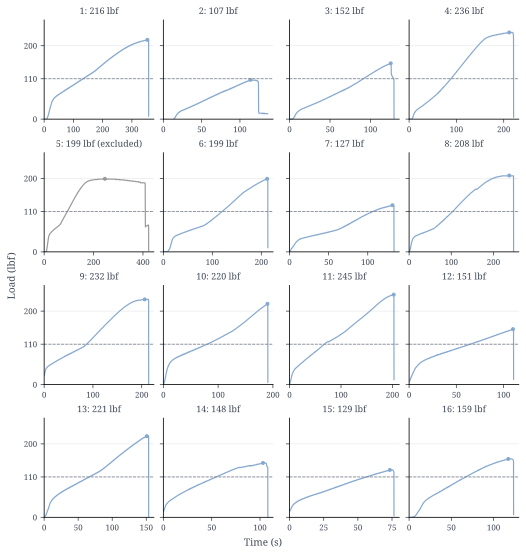

In [6]:
fig, axes = plt.subplots(4, 4, sharey=True, figsize=(7.2, 7.6))
for ax, (number, trace) in zip(axes.flat, traces.items(), strict=True):
    time, load = trace["Time (s)"], trace["Load (lbf)"]
    peak = load.idxmax()
    color = "0.6" if number in EXCLUDED else "C0"
    ax.plot(time, load, color=color, linewidth=1.2)
    ax.plot(time[peak], load[peak], "o", color=color, markersize=3)
    plot_reference(ax, 110)
    ax.set(
        title=f"{number}: {load[peak]:.0f} lbf"
        + (" (excluded)" if number in EXCLUDED else ""),
        xlim=(0, time.max() * 1.05),
        ylim=(0, 270),
        yticks=[0, 110, 200],
    )
    ax.tick_params(labelsize=8)
    ax.title.set_fontsize(9)
fig.supxlabel("Time (s)", fontsize=10)
fig.supylabel("Load (lbf)", fontsize=10)
fig.savefig(OUT / "force_traces.svg")
fig.savefig(OUT / "force_traces.png", dpi=200)
plt.show()

#### 3a. Check the assumptions

Use plots to check whether your failure strength data can be considered **i.i.d.**, **normally distributed**, and **free of outliers**.

- A plot against test order checks for trends or shifts (independence, identical distribution).
- A histogram and a normal probability plot check normality.
- A box plot flags outliers.

### 3a. Assumption checks

Dashed lines mark 110 lbf.

In [7]:
q1, q3 = np.percentile(x, [25, 75])
fences = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

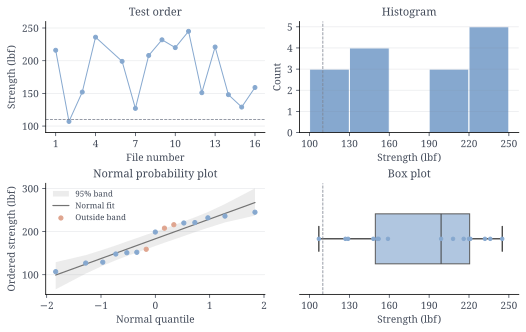

In [8]:
x_sorted = np.sort(x)
z = stats.norm.ppf((np.arange(1, n + 1) - 0.5) / n)
reference = np.random.default_rng(23103).standard_normal((20_000, n))
reference.sort(axis=1)
reference -= reference.mean(axis=1, keepdims=True)
reference /= reference.std(axis=1, ddof=1, keepdims=True)
normal_lo, normal_hi = xbar + s * np.quantile(reference, [0.025, 0.975], axis=0)
fig, axes = plt.subplots(2, 2, figsize=(7.2, 4.5))
axes[1, 1].sharex(axes[0, 1])
ax = axes[0, 0]
ax.plot(strengths["File"], x, "o-", markersize=4, linewidth=1)
plot_reference(ax, 110)
ax.set(
    title="Test order",
    xlabel="File number",
    ylabel="Strength (lbf)",
    xticks=[1, 4, 7, 10, 13, 16],
    ylim=(90, 260),
)
ax = axes[0, 1]
edges = np.arange(100, 251, 30)
ax.hist(x, bins=edges, color="C0", edgecolor="white")
plot_reference(ax, 110, vertical=True)
ax.set(
    title="Histogram",
    xlabel="Strength (lbf)",
    ylabel="Count",
    xticks=edges,
    yticks=range(6),
)
ax = axes[1, 0]
ax.fill_between(
    z, normal_lo, normal_hi, color="0.5", alpha=0.15, lw=0, label="95% band"
)
ax.plot(z, xbar + s * z, color="0.45", linewidth=1.2, label="Normal fit")
outside = (x_sorted < normal_lo) | (x_sorted > normal_hi)
ax.scatter(z[~outside], x_sorted[~outside], s=18, color="C0", zorder=3)
ax.scatter(
    z[outside], x_sorted[outside], s=18, color="C2", zorder=3, label="Outside band"
)
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set(
    title="Normal probability plot",
    xlabel="Normal quantile",
    ylabel="Ordered strength (lbf)",
)
ax = axes[1, 1]
ax.boxplot(
    x,
    orientation="horizontal",
    widths=0.45,
    patch_artist=True,
    boxprops={"facecolor": "C0", "alpha": 0.65},
    medianprops={"color": "0.25"},
)
ax.scatter(x, np.ones(n), s=12, color="C0", zorder=3)
plot_reference(ax, 110, vertical=True)
ax.spines.left.set_visible(False)
ax.set(title="Box plot", xlabel="Strength (lbf)", yticks=[])
fig.savefig(OUT / "assumption_checks.svg")
fig.savefig(OUT / "assumption_checks.png", dpi=200)
plt.show()

**Are the data independent, normal, and free of outliers? Refer to your observations of the plots:**

The test-order plot shows no trend; several late tests are low, but so are files 2 and 7. The plots cannot show that the brushes were sampled independently from production, so we assume it. The probability plot is close to the line except for a gap from 159 to 199 lbf, and three middle points fall just outside the shaded 95% band from simulated normal samples, so normality is a reasonable working assumption. There are no outliers: every value is inside the box-plot fences (43, 327) lbf.

#### 3b. Sample statistics

Calculate the sample size $n$, sample mean $\bar{x}$, sample median $\tilde{x}$, and sample standard deviation $s$.

### 3b. Sample statistics

In [9]:
sample_stats = pd.DataFrame(
    {"n": [n], "Mean (lbf)": [xbar], "Median (lbf)": [xmed], "Sample SD (lbf)": [s]}
)
styled_table(sample_stats, precision=2).set_table_styles(
    [
        {"selector": "", "props": "width: auto;"},
        {"selector": "thead th:first-child", "props": "width: auto;"},
    ],
    overwrite=False,
)

n,Mean (lbf),Median (lbf),Sample SD (lbf)
15,183.33,199.00,45.86


---

## Analyze Data

### 4. Two estimates of the 10th percentile

Use two different methods to estimate the 10th percentile of the failure strength distribution (lbs).

a. **Method 1 (normal model).** Assume the data come from a normal distribution and use
$$\text{E1} = \bar{x} - 1.28 \times s,$$
where $-1.28 \approx z_{0.10}$ is the 10th percentile of the standard normal. Call this number **E1**.

b. **Method 2 (sample percentile).** Calculate the sample 10th percentile as described below and in Example 5.7.1 and Table 5.7.1 of the textbook. Use linear interpolation if necessary. Call this number **E2**.

#### Sample percentiles

Given a sample $x_1, x_2, \ldots, x_n$, order it from smallest to largest and write the ordered data as $x_{(1)}, x_{(2)}, \ldots, x_{(n)}$.

The $j$-th ordered value $x_{(j)}$ is called the $100(j - 0.5)/n$ **th percentile** of the sample, since it has $100(j - 0.5)/n$ % of the data below it. For a percentile that falls between $100(j - 0.5)/n$ and $100(j + 0.5)/n$, linearly interpolate between $x_{(j)}$ and $x_{(j+1)}$.

**Example 5.7.1 (Battery life).** Ten observations of battery service life (minutes): 176, 191, 214, 220, 205, 192, 201, 190, 183, 185.

| $j$ | $x_{(j)}$ | $(j - 0.5)/10$ | $z_j$ |
|---:|---:|---:|---:|
| 1 | 176 | 0.05 | -1.64 |
| 2 | 183 | 0.15 | -1.04 |
| 3 | 185 | 0.25 | -0.67 |
| 4 | 190 | 0.35 | -0.39 |
| 5 | 191 | 0.45 | -0.13 |
| 6 | 192 | 0.55 | 0.13 |
| 7 | 201 | 0.65 | 0.39 |
| 8 | 205 | 0.75 | 0.67 |
| 9 | 214 | 0.85 | 1.04 |
| 10 | 220 | 0.95 | 1.64 |

The 10th percentile (0.10) lies halfway between 0.05 and 0.15, so it is halfway between $x_{(1)} = 176$ and $x_{(2)} = 183$: **179.5**.

The code below reproduces this. `np.interp` does the linear interpolation, and `np.percentile(..., method='hazen')` uses the same $(j - 0.5)/n$ rule.

In [10]:
battery = np.array([176, 191, 214, 220, 205, 192, 201, 190, 183, 185])

ordered = np.sort(battery)
j = np.arange(1, len(ordered) + 1)
p_j = (j - 0.5) / len(ordered)

print("By interpolation:", np.interp(0.10, p_j, ordered))
print("np.percentile:   ", np.percentile(battery, 10, method="hazen"))

By interpolation: 179.5
np.percentile:    179.5


### 4. Estimates of the 10th percentile

**E1 (normal model):** E1 $=\bar{x}-1.28s$.

**E2 (sample percentile):** with positions $(j-0.5)/n$, the 10th percentile falls at $j=0.10n+0.5=2$, so E2 $=x_{(2)}$ and no interpolation is needed.

In [11]:
E1 = xbar - 1.28 * s
E2 = np.percentile(x, 10, method="hazen")

**E1 = 124.63 lbf; E2 = 127.00 lbf.**

---

## Select Best Estimator and Find Estimation Error

### 5. Simulation

Simulate **10,000** data sets, each of size $n$, from a normal distribution with mean $\bar{x}$ and standard deviation $s$ from step 3b.

Because the simulated data really are draws from $N(\bar{x}, s^2)$, the **true** 10th percentile is known: it is the number you calculated in 4a. Both estimators are estimating that number.

**5a.** Calculate the two estimators (as in 4a and 4b) for each of the 10,000 simulated data sets.

_Hint:_ `np.mean`, `np.std` and `np.percentile` all accept `axis=1`, which applies the function to each row.

### 5a. Simulation

We simulated 10,000 samples of size 15 from $N(\bar{x}, s^2)$ (seed 12345) and computed E1 and E2 for each.

In [12]:
B = 10_000
true_p10 = stats.norm.ppf(0.10, loc=xbar, scale=s)
sims = np.random.default_rng(12345).normal(xbar, s, size=(B, n))
estimates = np.column_stack(
    (
        sims.mean(axis=1) - 1.28 * sims.std(axis=1, ddof=1),
        np.percentile(sims, 10, axis=1, method="hazen"),
    )
)
errors = estimates - true_p10
S1, S2 = estimates.std(axis=0, ddof=1)
performance = pd.DataFrame(
    {
        "Estimator": ["E1", "E2"],
        "Mean (lbf)": estimates.mean(axis=0),
        "Median (lbf)": np.median(estimates, axis=0),
        "SD (lbf)": [S1, S2],
        "Bias (lbf)": errors.mean(axis=0),
        "MSE (lbf²)": (errors**2).mean(axis=0),
    }
)
performance.round(2).to_csv(OUT / "estimator_comparison.csv", index=False)

The model's true 10th percentile is **124.56 lbf**, using the exact $z_{0.10}=-1.2816$. E1 is 0.07 lbf higher because it uses 1.28.

**5b.** Compare the distributions of the two estimators with plots and descriptive statistics.

**Compare the two distributions:**

**5c.** Find the standard deviation of each estimator across the 10,000 simulated samples. Call these **S1** (for the estimator used to calculate E1) and **S2**.

**5d.** Estimate the **bias** and **mean squared error** of each estimator:
$$\text{bias} = \frac{1}{10{,}000}\sum_{i=1}^{10{,000}}(\hat\theta_i - \theta), \qquad \text{MSE} = \frac{1}{10{,}000}\sum_{i=1}^{10{,}000} \big(\hat\theta_i - \theta\big)^2,$$
where $\theta$ is `true_p10` and $\hat\theta_i$ is the estimate from simulated data set $i$.

### 5b-d. Sampling distributions, spread, bias, and MSE

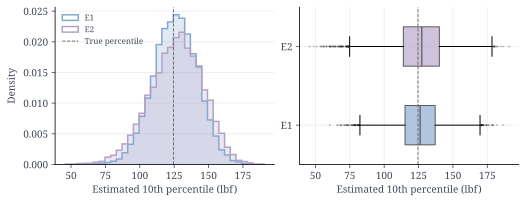

Estimator,Mean (lbf),Median (lbf),SD (lbf),Bias (lbf),MSE (lbf²)
E1,125.95,126.11,16.09,1.39,260.67
E2,126.49,127.37,19.37,1.93,378.85


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7))
bins = np.linspace(estimates.min(), estimates.max(), 36)
for i, label in enumerate(["E1", "E2"]):
    style = {"bins": bins, "density": True, "color": f"C{i}"}
    axes[0].hist(estimates[:, i], histtype="stepfilled", alpha=0.25, **style)
    axes[0].hist(estimates[:, i], histtype="step", lw=1.5, label=label, **style)
boxes = axes[1].boxplot(
    estimates,
    orientation="horizontal",
    tick_labels=["E1", "E2"],
    patch_artist=True,
    widths=0.5,
    medianprops={"color": "0.25"},
    flierprops={"marker": ".", "markersize": 2, "alpha": 0.25},
)
for i, box in enumerate(boxes["boxes"]):
    box.set_facecolor(f"C{i}")
    box.set_alpha(0.65)
for ax in axes:
    ax.axvline(true_p10, color="0.4", ls="--", lw=0.9, label="True percentile")
    ax.set_xlabel("Estimated 10th percentile (lbf)")
axes[0].set_ylabel("Density")
axes[0].legend(frameon=False, fontsize=8)
axes[1].grid(axis="x", alpha=0.15)
fig.savefig(OUT / "estimator_distributions.svg")
fig.savefig(OUT / "estimator_distributions.png", dpi=200)
plt.show()
styled_table(performance, precision=2)

Both estimators center slightly above the true value (bias 1.39 and 1.93 lbf). E1 is nearly symmetric; E2 is wider and has a longer lower tail.

**5e.** Given the analysis in 5b to 5d, would you use E1 or E2 as the best estimate of the 10th percentile of brush strength if the data really are normally distributed?

**Your response:**

### 5e. Estimator choice

We chose **E1**. If the strengths are normal, it varies less than E2 (S1 = 16.09 vs. S2 = 19.37 lbf) and has 31% lower MSE (260.67 vs. 378.85 lbf²).

**5f.** Calculate the interval
$$\text{E1} \pm 1.96\,\text{S1} \qquad \text{or} \qquad \text{E2} \pm 1.96\,\text{S2}$$
from your failure strength data, depending on which estimator you chose in 5e.

This is an approximate 95% confidence interval, since both estimators are approximately normally distributed. Neither estimator is a sample mean from normally distributed data, so the $t$-distribution does not apply.

### 5f. Approximate 95% confidence interval

In [14]:
lower, upper = E1 - 1.96 * S1, E1 + 1.96 * S1

In [15]:
all_x = peaks.to_numpy(dtype=float)
all_sims = np.random.default_rng(12345).normal(
    all_x.mean(), all_x.std(ddof=1), (B, all_x.size)
)
all_E1 = all_x.mean() - 1.28 * all_x.std(ddof=1)
all_S1 = (all_sims.mean(axis=1) - 1.28 * all_sims.std(axis=1, ddof=1)).std(ddof=1)
sensitivity = pd.DataFrame(
    {
        "Data": ["Exclude file 5", "All 16 files"],
        "n": [n, all_x.size],
        "E1 (lbf)": [E1, all_E1],
        "95% lower (lbf)": [lower, all_E1 - 1.96 * all_S1],
        "95% upper (lbf)": [upper, all_E1 + 1.96 * all_S1],
    }
)
sensitivity.round(2).to_csv(OUT / "exclusion_sensitivity.csv", index=False)

E1 $\pm$ 1.96 S1 = 124.63 $\pm$ 31.53 lbf, so the approximate 95% confidence interval for the 10th-percentile strength is **(93.10, 156.16) lbf**. The lower bar repeats the calculation with all 16 files.

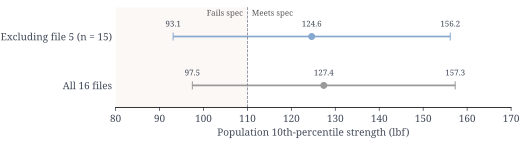

In [16]:
fig, ax = plt.subplots(figsize=(7.2, 1.9))
rows = [(E1, S1, "C0"), (all_E1, all_S1, "0.6")]
for row, (point, spread, color) in enumerate(rows):
    ends = point + np.array([-1, 1]) * 1.96 * spread
    ax.errorbar(point, 1 - row, xerr=1.96 * spread, fmt="o", color=color, capsize=4)
    for value in [ends[0], point, ends[1]]:
        ax.annotate(
            f"{value:.1f}",
            (value, 1 - row),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center",
            fontsize=8,
        )
ax.axvspan(80, 110, color="C2", alpha=0.08, lw=0)
plot_reference(ax, 110, vertical=True)
for x_text, ha, text in [(109, "right", "Fails spec"), (111, "left", "Meets spec")]:
    ax.text(x_text, 1.55, text, ha=ha, va="top", fontsize=8, color="0.35")
ax.set(
    xlabel="Population 10th-percentile strength (lbf)",
    xlim=(80, 170),
    ylim=(-0.45, 1.6),
    yticks=[1, 0],
    yticklabels=["Excluding file 5 (n = 15)", "All 16 files"],
)
ax.spines.left.set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(False)
fig.savefig(OUT / "decision_interval.svg")
fig.savefig(OUT / "decision_interval.png", dpi=200)
plt.show()

In [17]:
fail_fit = stats.norm.cdf(110, xbar, s)  # share below 110 lbf
fail_low = stats.norm.cdf(110, lower - stats.norm.ppf(0.10) * s, s)
n_even = int(np.ceil(n * (1.96 * S1 / (E1 - 110)) ** 2))


def p_clear(m):
    # Share of simulated m-test data sets whose interval lies above 110 lbf
    new = np.random.default_rng(12345).normal(xbar, s, size=(B, m))
    new_s = new.std(axis=1, ddof=1)
    new_E1 = new.mean(axis=1) - 1.28 * new_s
    return np.mean(new_E1 - 1.96 * S1 * np.sqrt(n / m) * new_s / s > 110)


n_80 = n_even
while p_clear(n_80) < 0.8:
    n_80 += 5

---

## Make and Present a Decision

### 6. Make a decision

_This can be done during the lab session if you have time._

You now have an estimate of the 10th percentile and an estimate of how far off it might be. Study the interval from 5f.

i. If the interval is **completely above 110 lbs**, you can be 95% confident that 90% of your brushes will not fail at 110 lbs.

ii. If the interval **contains 110 lbs**, you probably need to break more brushes, since the estimate has too much error for a conclusive decision.

iii. If the interval is **completely below 110 lbs**, you can be 95% confident that the process needs to be adjusted to increase failure strength, since more than 10% of the brushes will fail at 110 lbs.

**Your decision:**

### 6. Decision

**More failure tests are needed.** The interval (93.10, 156.16) lbf contains 110 lbf, so we cannot say with 95% confidence whether more than 90% of brushes withstand 110 lbf. Fourteen of 15 brushes held 110 lbf, but 15 tests are too few to pin down the weakest 10% of brushes. The fitted model puts 5.5% of brushes below 110 lbf; if the 10th percentile were at the interval's lower end, 18% would be. With all 16 files the interval is (97.47, 157.28) lbf, so the exclusion does not change the decision.

Since S1 scales with $1/\sqrt{n}$, the interval would just reach 110 lbf at $n=15\,(1.96\,\text{S1}/(\text{E1}-110))^2\approx70$ tests if $\bar{x}$ and $s$ stayed the same. New data will move both, though: simulating from the current fit, a 70-test interval clears 110 lbf only about half the time, and about 145 tests give an 80% chance. We recommend about 130 more tests on brushes from several production runs.

### 7. Present your decision

Make a video **under 3 minutes**, in two distinct parts. All team members should have a chance to speak.
You may use _Panopto_ to make this video recording.

a. **First 1 to 2 minutes: summarize your data exploration and simulation, and defend your choice of E1 or E2.** Use clear plots. Address this part to **Tyler Shada**, chief engineer at the brush plant and a Six Sigma Master Blackbelt who is fully capable of following the statistical methods. Convince him that you used the lab data correctly.

b. **Last minute or less: justify your decision** to

   i. request more resources for additional testing,

   ii. add cost to the process to strengthen the brush handles, or

   iii. leave the process as it is because there will be no field problem.
   
   Address this part to **Courtney Lytle**, VP of Manufacturing, an MBA with an engineering background. She trusts that the statistics are correct, but she needs to understand your decision and be convinced it is the right one.

### 7. Presentation script

**Vivian, 0:00-0:32** (force-time graphs/traces)

Mr. Shada, we used 15 of our 16 files and took the peak load as each brush's strength. In file 5 the load flattens near 199 pounds, and the video shows the fixture moving while the brush stays in one piece, so that peak isn't actually a joint failure. File 6 retests the same brush, so we counted it once. We kept brush 2 at 107. Even though it's below spec, it's still a valid failure.

**Mosawer, 0:32-1:04** (assumptions)

There's no trend with test order and no outliers in the box plot. The normal plot is close to a line except for a mild gap between 159 and 199, so assuming normality is pretty reasonable. E1, the mean minus 1.28 standard deviations, is 124.6 pounds. E2, the sample tenth percentile, is 127. They agree within three pounds.

**Victor, 1:04-1:42** (distributions/interval plot)

We simulated 10,000 samples of 15 from that normal fit. Both estimators come out less than two pounds high, but E1 is tighter: a standard deviation of 16.1 against 19.4, and 31 percent lower MSE (mean squared error). So we chose E1. E1 plus or minus 1.96 times 16.1 gives 93 to 156 pounds, which contains 110. With all 16 files it's 97 to 157, so dropping file five doesn't actually change that.

**Conor, 1:42-2:30** (interval plot)

Ms. Lytle, we recommend paying for more testing. Fourteen of fifteen brushes held 110 pounds, and our best estimate is that around 5 percent would fail, under the 10 percent limit. But only fifteen brushes doesn't rule out a failure rate close to one in five. Leaving the process as it is risks warranty issues, and strengthening the handles adds cost to every brush for a problem we might not actually have. We'd test about 130 more brushes from several production runs. If the process is as good as it seems here, that gives about an 80 percent chance of a clear answer. If the range then sits above 110, we should leave the process alone. If it sits below, we should strengthen the handles.

## Post-lab Submission

1. Submit your video presentation on Canvas.
2. Submit your completed notebook as a pdf on Crowdmark.
3. Submit your spreadsheet (.csv or Excel format) of recorded failure strength on Crowdmark.

### Calculation code

In [18]:
code_appendix("Hair_Brush_Post_Lab.ipynb")